# FITS 交互式 mask 编辑器

依次运行下方单元格，默认编辑 `subhalo_0946/data/image.fits`，保存到同目录的 `mask.fits`。
修改 `IMAGE_PATH` 可切换其他图像。示例先用 Astropy 读取 `image` 数组，再传给 `FitsMaskEditor`；
也可以直接传入残差图、裁剪图等二维数组。

- 鼠标悬停：实时显示像素坐标、原图数值和 mask 值。
- **按住 Ctrl + 移动鼠标**：绘制；**按住 Shift + 移动鼠标**：擦除，无须按住鼠标按键。
- `Diameter (px)` 滑块：调整圆形笔刷直径。
- `Save mask (overwrite)`：将最新结果保存到 `OUTPUT_PATH`，标记为 1，未标记为 0。
- 图中 `Save to` 只显示简短位置提示；完整保存路径在下方配置单元格中设置和打印。
- 先点击图像让画布获得键盘焦点。如果快捷键被截获，选择 `Paint` / `Erase` 后左键拖动。
- 工具栏平移/缩放期间暂停绘制，退出该模式后继续。

环境依赖：`numpy`、`astropy`、`matplotlib`、`ipympl`。如缺少 `ipympl`，在当前 kernel 环境中安装后重启 kernel。


In [20]:
%matplotlib widget


In [21]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
from IPython.display import display

# Support launching this notebook from the tool directory or repository root.
TOOL_DIR = Path.cwd()
if not (TOOL_DIR / "mask_tool.py").exists():
    TOOL_DIR = TOOL_DIR / "examples" / "mask_tool"
sys.path.insert(0, str(TOOL_DIR))
# Reload the module to use the latest code instead of the kernel import cache.
import mask_tool
mask_tool = importlib.reload(mask_tool)
FitsMaskEditor = mask_tool.FitsMaskEditor


In [22]:
# Use the observed image from subhalo_0946 by default.
DATA_DIR = Path("/home/xycao/workspace/tinylens_dev/TinyLensGpu/examples/pix_src_demo_operator/pipe/subhalo_0946/data")
IMAGE_PATH = DATA_DIR / "image.fits"
OUTPUT_PATH = DATA_DIR / "mask.fits"

# Read FITS outside the editor. This image is in the primary HDU; use ext="SCI" if needed.
image, image_header = fits.getdata(IMAGE_PATH, ext=0, header=True)

print(f"Image: {IMAGE_PATH}")
print(f"Image array: shape={image.shape}, dtype={image.dtype}")
print(f"Mask output: {OUTPUT_PATH}")


Image: /home/xycao/workspace/tinylens_dev/TinyLensGpu/examples/pix_src_demo_operator/pipe/subhalo_0946/data/image.fits
Image array: shape=(201, 201), dtype=>f4
Mask output: /home/xycao/workspace/tinylens_dev/TinyLensGpu/examples/pix_src_demo_operator/pipe/subhalo_0946/data/mask.fits


Tool code: /home/xycao/workspace/tinylens_dev/TinyLensGpu/examples/mask_tool/mask_tool.py


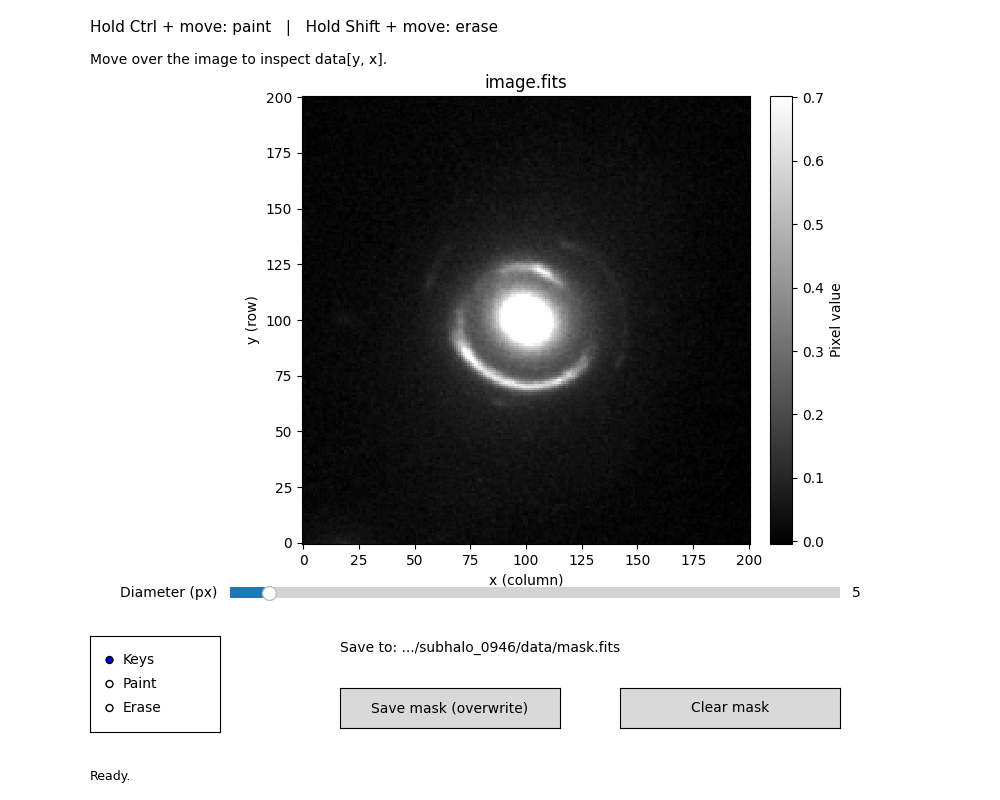

In [24]:
# Use ioff + display to avoid displaying the same canvas twice.
# Save before rerunning this cell; a new editor reinitializes the mask.
if "editor" in globals():
    plt.close(editor.fig)

# Reload the code and rebind the class even when rerunning only this cell.
import importlib
mask_tool = importlib.reload(importlib.import_module("mask_tool"))
FitsMaskEditor = mask_tool.FitsMaskEditor
print(f"Tool code: {Path(mask_tool.__file__).resolve()}")

with plt.ioff():
    editor = FitsMaskEditor(
        image,
        output_path=OUTPUT_PATH,
        header=image_header,         # Optional: preserve the corresponding WCS when saving the mask.
        title=IMAGE_PATH.name,
        brush_size=5,
        # initial_mask=fits.getdata(OUTPUT_PATH).astype(bool), # Optional: read the saved mask and pass its array.
        # vmin=0, vmax=20, cmap="gray", # Optional: customize the display limits and colormap.
    )
display(editor.fig.canvas)


## 从 Python 访问当前 mask

在图像上编辑后运行以下单元格，或直接点击图中的保存按钮。
内存中是 `bool` 数组；FITS 保存为 `uint8` 的 0/1 图像。`mask[y, x]` 与原图坐标完全对应。
关闭窗口不会自动保存。


In [ ]:
print("Mask shape:", editor.mask.shape)
print("Mask dtype:", editor.mask.dtype)
print("Marked pixels:", int(editor.mask.sum()))

# Uncomment to save from Python; the output file is overwritten by default.
# saved_path = editor.save()
# loaded_mask = fits.getdata(saved_path).astype(bool)
# assert np.array_equal(loaded_mask, editor.mask)


In [19]:
# saved_path = editor.save()
# loaded_mask = fits.getdata(saved_path).astype(bool)
# from matplotlib import pyplot as plt
# plt.figure(figsize=(10, 10))
# plt.imshow(loaded_mask, cmap='gray', origin='lower')
# plt.colorbar()
# plt.show()
